# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [ ]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

hi
device: cuda


###  Functions

In [ ]:
class GridGraph:
    '''
    The weighted graph G = (X, E, mu, w) built on lattice coordinates.

    grid   : list of (row, col) coordinates; vertex i is grid[i]. Two vertices are
             joined by an edge when their coordinates are horizontal or vertical
             neighbours. Use GridGraph.make_grid or GridGraph.grid_from_pattern.
    B      : observation set, as coordinates (row, col) or vertex indices.
    w      : edge weight. possible inputs:
               float       -> w_xy = w on every edge
               dict        -> {((r1, c1), (r2, c2)): w_xy}, either order; edges
                              not listed get w_default
               callable    -> w_xy = w(p, q) for the coordinates p, q of an edge
               "random"    -> w_xy ~ Uniform(w_low, w_high), drawn with w_seed
               n x n array -> used as given (must be symmetric, zero off the lattice edges)
             A weight of 0 removes that edge.
    mu     : vertex centrality. possible inputs:
               "constant"     -> mu_x = mu_val for all x
               "deg"          -> mu_x = deg(x), the number of edges at x
               "weighted_deg" -> mu_x = sum_y w_xy
               array-like     -> mu_x = mu[x], one positive value per vertex (grid order)
    mu_val : the constant used when mu="constant".
    w_default, w_low, w_high, w_seed : see `w` above.

    Attributes W (n x n, symmetric), mu (n,), deg (n,), B (|B|,) are torch tensors.
    Raises ValueError if the graph is disconnected or Assumption 1 (ii) fails.
    '''

    def __init__(self, grid, B, w=1.0, mu="deg", mu_val=1.0,
                 w_default=1.0, w_low=0.1, w_high=1.0, w_seed=0):
        self.grid = [tuple(p) for p in grid]
        self.index = self._build_index(self.grid)
        self.n = len(self.grid)
        self.edges = self._lattice_edges()
        self.W = self._build_weights(w, w_default, w_low, w_high, w_seed)
        self.deg = (self.W > 0).sum(dim=1).to(torch.float64)
        self.mu = self._build_mu(mu, mu_val)
        self.B = self._build_B(B)
        self._check_connected()
        self._check_assumption()

    @staticmethod
    def make_grid(rows, cols):
        '''
        All lattice coordinates (row, col) of a rows x cols rectangular grid, row by row.
        Row 0 is drawn at the top.
        '''
        return [(r, c) for r in range(rows) for c in range(cols)]

    @staticmethod
    def grid_from_pattern(pattern, node="X"):
        '''
        Coordinates from a picture of the graph, one string per row (row 0 on top).
        Characters equal to `node` (case-insensitive) are vertices, anything else is empty;
        spaces are ignored. Example: ["XooX", "XXXX"].
        '''
        rows = [line.replace(" ", "") for line in pattern]
        return [(r, c) for r, line in enumerate(rows)
                for c, ch in enumerate(line) if ch.upper() == node.upper()]

    @staticmethod
    def _build_index(grid):
        index = {p: i for i, p in enumerate(grid)}
        if len(index) != len(grid):
            raise ValueError("grid contains duplicate coordinates")
        return index

    def _lattice_edges(self):
        '''Pairs (i, j), i < j in grid order, of horizontally/vertically adjacent vertices.'''
        edges = []
        for (r, c), i in self.index.items():
            for dr, dc in [(0, 1), (1, 0)]:
                j = self.index.get((r + dr, c + dc))
                if j is not None:
                    edges.append((min(i, j), max(i, j)))
        return sorted(edges)

    def _build_weights(self, w, w_default, w_low, w_high, w_seed):
        n = self.n
        if isinstance(w, (torch.Tensor, np.ndarray)) and np.ndim(w) == 2:
            W = torch.as_tensor(w, dtype=torch.float64).clone()
            if W.shape != (n, n):
                raise ValueError(f"W has shape {tuple(W.shape)}, expected ({n}, {n})")
            if not torch.allclose(W, W.T):
                raise ValueError("W must be symmetric")
            mask = torch.zeros(n, n, dtype=torch.bool)
            for i, j in self.edges:
                mask[i, j] = mask[j, i] = True
            if (W[~mask] != 0).any():
                raise ValueError("W is nonzero on a pair that is not a lattice edge")
        else:
            if isinstance(w, str):
                if w != "random":
                    raise ValueError("w must be a number, dict, callable, 'random' or an n x n array")
                gen = torch.Generator().manual_seed(w_seed)
                vals = w_low + (w_high - w_low) * torch.rand(len(self.edges), generator=gen,
                                                             dtype=torch.float64)
                weight = dict(zip(self.edges, vals.tolist()))
                edge_weight = lambda i, j: weight[(i, j)]
            elif isinstance(w, dict):
                wd = {(tuple(p), tuple(q)): float(v) for (p, q), v in w.items()}
                for p, q in wd:
                    if p not in self.index or q not in self.index:
                        raise ValueError(f"w has a key {(p, q)} that is not in the grid")
                edge_weight = lambda i, j: wd.get((self.grid[i], self.grid[j]),
                                                  wd.get((self.grid[j], self.grid[i]), w_default))
            elif callable(w):
                edge_weight = lambda i, j: float(w(self.grid[i], self.grid[j]))
            else:
                edge_weight = lambda i, j: float(w)

            W = torch.zeros(n, n, dtype=torch.float64)
            for i, j in self.edges:
                W[i, j] = W[j, i] = edge_weight(i, j)

        if (W < 0).any():
            raise ValueError("edge weights must be nonnegative")
        return W

    def _build_mu(self, mu, mu_val):
        n = self.n
        if isinstance(mu, str):
            if mu == "constant":
                mu = torch.full((n,), float(mu_val), dtype=torch.float64)
            elif mu == "deg":
                mu = self.deg.clone()
            elif mu == "weighted_deg":
                mu = self.W.sum(dim=1)
            else:
                raise ValueError("mu must be 'constant', 'deg', 'weighted_deg' or an array of length n")
        else:
            mu = torch.as_tensor(mu, dtype=torch.float64).flatten()
            if mu.numel() != n:
                raise ValueError(f"mu has {mu.numel()} entries, expected {n}")
        if (mu <= 0).any():
            raise ValueError("vertex centrality mu must be positive")
        return mu

    def _build_B(self, B):
        B = torch.tensor([self.index[tuple(b)] if isinstance(b, (tuple, list)) else int(b)
                          for b in B], dtype=torch.long)
        if len(set(B.tolist())) != len(B):
            raise ValueError("B contains duplicate vertices")
        return B

    def _check_connected(self):
        '''Breadth-first search from vertex 0 over edges with w_xy > 0.'''
        seen, frontier = {0}, [0]
        while frontier:
            x = frontier.pop()
            for y in torch.nonzero(self.W[x]).flatten().tolist():
                if y not in seen:
                    seen.add(y)
                    frontier.append(y)
        if len(seen) != self.n:
            raise ValueError("graph is not connected")

    def _check_assumption(self):
        '''Assumption 1 (ii): mu_x >= sum_y w_xy, so that p_xx >= 0.'''
        bad = torch.nonzero(self.mu < self.W.sum(dim=1) - 1e-12).flatten().tolist()
        if bad:
            raise ValueError(f"Assumption 1 (ii) violated at vertices {bad}: mu_x < sum_y w_xy")

    def transition_matrix(self):
        '''P (n x n) for this graph; see transition_matrix(W, mu).'''
        return transition_matrix(self.W, self.mu)


def transition_matrix(W, mu):
    '''
    W size: n x n
    mu size: n

    Function returns P (n x n)
    '''
    P = W / mu[:, None]
    stay = 1.0 - P.sum(dim=1)
    if (stay < -1e-12).any():
        raise ValueError("Assumption violated: mu_x < sum_y w_xy for some x")
    return P + torch.diag(stay.clamp_min(0.0))

In [4]:
def exact_first_passage_literal(P, B, t_max):
    '''
    r(1, x, y) = p_xy
    r(t, x, y) = sum_{z != y} p_xz * r(t-1, z, y),   t >= 2

    Returns r with r[t-1, i, j] = r(t, B[i], B[j]), shape (t_max, |B|, |B|).
    '''
    P = P.cpu().double()
    n = P.shape[0]

    @lru_cache(maxsize=None)
    def r(t, x, y):
        if t == 1:
            return P[x, y].item()
        return sum(P[x, z].item() * r(t - 1, z, y)
                   for z in range(n) if z != y)

    return torch.tensor([[[r(t, int(x), int(y)) for y in B] for x in B]
                         for t in range(1, t_max + 1)], dtype=torch.float64)

#### Empirical first passage distribution $r'$ (Monte Carlo)

In [ ]:
@torch.no_grad()
def empirical_first_passage(P, B, t_max, n_walks=10**6, batch=10**6, seed=0):
    '''
    Returns r' with
        r'[t-1, i, j] = (# walks from B[i] that first hit B[j] at step t) / n_walks.

    Each ordered pair (i, j) gets its own independent n_walks walks. Walks that
    have not hit the target by step t_max are censored (tau = inf) and dropped.
    '''
    gen = torch.Generator(device=device).manual_seed(seed)
    P, B = P.to(device), B.to(device)
    nB = len(B)
    n_pairs = nB * nB

    cdf = torch.cumsum(P, dim=1).float()
    cdf[:, -1] = 1.0
    starts  = B.repeat_interleave(nB)
    targets = B.repeat(nB)
    counts = torch.zeros(n_pairs, t_max + 1, dtype=torch.long, device=device)

    done = 0
    while done < n_walks:
        m = min(batch, n_walks - done)
        state = starts[:, None].expand(n_pairs, m).clone()
        tgt = targets[:, None].expand(n_pairs, m)
        hit_time = torch.zeros(n_pairs, m, dtype=torch.long, device=device)
        alive = torch.ones(n_pairs, m, dtype=torch.bool, device=device)

        for s in range(1, t_max + 1):
            u = torch.rand(n_pairs, m, 1, generator=gen, device=device)
            nxt = (u > cdf[state]).sum(dim=-1)
            state = torch.where(alive, nxt, state)
            new_hit = alive & (state == tgt)
            hit_time[new_hit] = s
            alive &= ~new_hit
            if not alive.any():
                break
        offs = torch.arange(n_pairs, device=device)[:, None] * (t_max + 1)
        counts += torch.bincount((hit_time + offs).flatten(),
                                 minlength=n_pairs * (t_max + 1)).view(n_pairs, t_max + 1)
        done += m

    r_emp = counts[:, 1:].double() / n_walks
    return r_emp.T.reshape(t_max, nB, nB).cpu()

#### Error metric

In [ ]:
def frne(r, r_emp):
    r, r_emp = r.cpu().double(), r_emp.cpu().double()
    return (torch.linalg.norm(r - r_emp) / torch.linalg.norm(r)).item() * 100

In [ ]:
B_COLOR, X_COLOR, EDGE_COLOR = "white", "#4cc3e6", "black"
EXACT_COLOR, EMP_COLOR = "#2a6fdb", "#e8833a"


def plot_graph(grid, B, values=None, title=None, ax=None, cmap="viridis", W=None):
    '''
    Draw the grid graph with row 0 at the top.
    B may be coordinates or vertex indices. If `values` (length n) is given,
    vertices are colored by value with a colorbar; otherwise color by membership in B.
    If `W` (n x n) is given, edge width scales with w_xy and each edge is labelled
    with its weight; edges with w_xy = 0 are not drawn.
    '''
    coords = [tuple(p) for p in grid]
    index = {p: i for i, p in enumerate(coords)}
    B_idx = {index[tuple(b)] if isinstance(b, (tuple, list)) else int(b) for b in B}
    xy = np.array([(c, -r) for r, c in coords], dtype=float)

    if ax is None:
        _, ax = plt.subplots(figsize=(1.3 * (np.ptp(xy[:, 0]) + 2), 1.3 * (np.ptp(xy[:, 1]) + 2)))
    for (r, c), i in index.items():
        for dr, dc in [(0, 1), (1, 0)]:
            j = index.get((r + dr, c + dc))
            if j is None:
                continue
            if W is None:
                ax.plot(*xy[[i, j]].T, color=EDGE_COLOR, lw=1.5, zorder=1)
            elif W[i, j] > 0:
                wij = float(W[i, j])
                ax.plot(*xy[[i, j]].T, color=EDGE_COLOR, lw=0.5 + 3.5 * wij / float(W.max()), zorder=1)
                ax.annotate(f"{wij:.2f}", xy[[i, j]].mean(axis=0), ha="center", va="center",
                            fontsize=7, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))

    if values is None:
        colors = [B_COLOR if i in B_idx else X_COLOR for i in range(len(coords))]
        ax.scatter(*xy.T, s=140, c=colors, edgecolors="black", linewidths=1, zorder=2)
        ax.scatter([], [], s=80, c=B_COLOR, edgecolors="black", label="vertex in $B$")
        ax.scatter([], [], s=80, c=X_COLOR, edgecolors="black", label=r"vertex in $X \setminus B$")
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    else:
        values = np.asarray(torch.as_tensor(values).cpu(), dtype=float)
        sc = ax.scatter(*xy.T, s=180, c=values, cmap=cmap, edgecolors="black",
                        linewidths=1, zorder=2)
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        bi = sorted(B_idx)
        ax.scatter(*xy[bi].T, s=180, facecolors="none", edgecolors="black",
                   linewidths=2.5, zorder=3)

    for i, (x, y) in enumerate(xy):
        ax.annotate(str(i), (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
    ax.set_aspect("equal")
    ax.margins(0.25)
    ax.axis("off")
    if title:
        ax.set_title(title)
    return ax


def _plot_fpt_grid(series, B, title):
    '''One panel per ordered pair (B[i], B[j]); `series` is a list of (r, label, color, kind).'''
    B = [int(b) for b in B]
    nB = len(B)
    t_max = series[0][0].shape[0]
    t = np.arange(1, t_max + 1)
    fig, axes = plt.subplots(nB, nB, figsize=(3.2 * nB, 2.4 * nB),
                             sharex=True, sharey=True, squeeze=False)
    for i in range(nB):
        for j in range(nB):
            ax = axes[i, j]
            for r, label, color, kind in series:
                vals = r[:, i, j].cpu().numpy()
                if kind == "bar":
                    ax.bar(t, vals, width=0.7, color=color, label=label)
                else:
                    ax.plot(t, vals, "o-", ms=4, lw=1.5, color=color, label=label)
            ax.set_title(f"$x = {B[i]},\\ y = {B[j]}$", fontsize=10)
            ax.grid(axis="y", color="0.9", lw=0.8)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            if i == nB - 1:
                ax.set_xlabel("$t$")
            if j == 0:
                ax.set_ylabel("probability")
    if len(series) > 1:
        axes[0, -1].legend(loc="upper right", frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


def plot_exact_distribution(r, B, title="Exact first passage distribution $r(t, x, y)$"):
    '''Bar chart of r(t, x, y) for t = 1..t_max and every (x, y) in B x B.'''
    return _plot_fpt_grid([(r, "exact $r$", EXACT_COLOR, "bar")], B, title)


def plot_empirical_distribution(r_emp, B, r=None,
                                title="Empirical first passage distribution $r'(t, x, y)$"):
    '''Bar chart of r'(t, x, y); if the exact r is given it is overlaid as a line.'''
    series = [(r_emp, "empirical $r'$", EMP_COLOR, "bar")]
    if r is not None:
        series.append((r, "exact $r$", EXACT_COLOR, "line"))
    return _plot_fpt_grid(series, B, title)


def summarize(P, B, r_emp, r_lit, paper_frne=None):
    '''Print FRNE and sanity checks for one experiment.'''
    r, r_emp, B_cpu = r_lit.cpu(), r_emp.cpu(), B.cpu()
    print("data shape (2T-1, |B|, |B|):", tuple(r.shape))
    msg = f"FRNE = {frne(r, r_emp):.6f}%"
    if paper_frne is not None:
        msg += f"   (paper: {paper_frne}%)"
    print(msg)
    print("check r(1, y, y) = p_yy:",
          torch.allclose(torch.diagonal(r[0]), torch.diagonal(P.cpu())[B_cpu]))
    print("probability mass observed by t = 2T-1 (exact):\n", r.sum(0).numpy().round(4))
    print("probability mass observed by t = 2T-1 (empirical):\n", r_emp.sum(0).numpy().round(4))

## Experiment 1: a graph with eight vertices

Constant ground-truth $\mu$ (Section 5.1, Figure 1): a $2 \times 4$ ladder with $|B| = 3$, $|X\setminus B| = 5$, $w_{xy} = 0.25$, $\mu_x = 1$, $T = 9$. The observed vertices are the right three vertices of the top row. Paper FRNE: $0.248499\%$.

Check of Assumption 1 (ii): every vertex has degree $\le 3$, so $\sum_y w_{xy} \le 0.75 \le 1 = \mu_x$.

Change any value in the parameter cell to run a variant.

In [ ]:
# ---- parameters (edit me) ----
grid1    = GridGraph.make_grid(2, 4)                      # 2 x 4 ladder, row 0 on top
B1_coord = [(0, 1), (0, 2), (0, 3)]             # observed vertices
w1       = 0.25                                 # edge weight
mu1_kind = "constant"                           # "constant", "deg", or an array of length |X|
mu1_val  = 1.0                                  # used when mu1_kind = "constant"
T1       = 9                                    # needs T >= |X|
N1       = 10**6                                # Monte Carlo walks per pair (x, y)
seed1    = 0

In [ ]:
G1 = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
W1, mu1, B1 = G1.W, G1.mu, G1.B
P1 = G1.transition_matrix()
t_max1 = 2 * T1 - 1                             # data needed for t = 1, ..., 2T-1
print(f"|X| = {len(mu1)}, |B| = {len(B1)}, T = {T1}, t_max = {t_max1}")

plot_graph(grid1, B1, title="Experiment 1: $X$ and $B$")
plot_graph(grid1, B1, values=mu1, title=r"Experiment 1: ground truth $\mu_x$")
plt.show()

In [10]:
r1_lit = exact_first_passage_literal(P1, B1, t_max1)
r1_emp = empirical_first_passage(P1, B1, t_max1, n_walks=N1, seed=seed1)

#summarize(P1, B1, r1_emp, r_lit=r1_lit, paper_frne=0.248499)

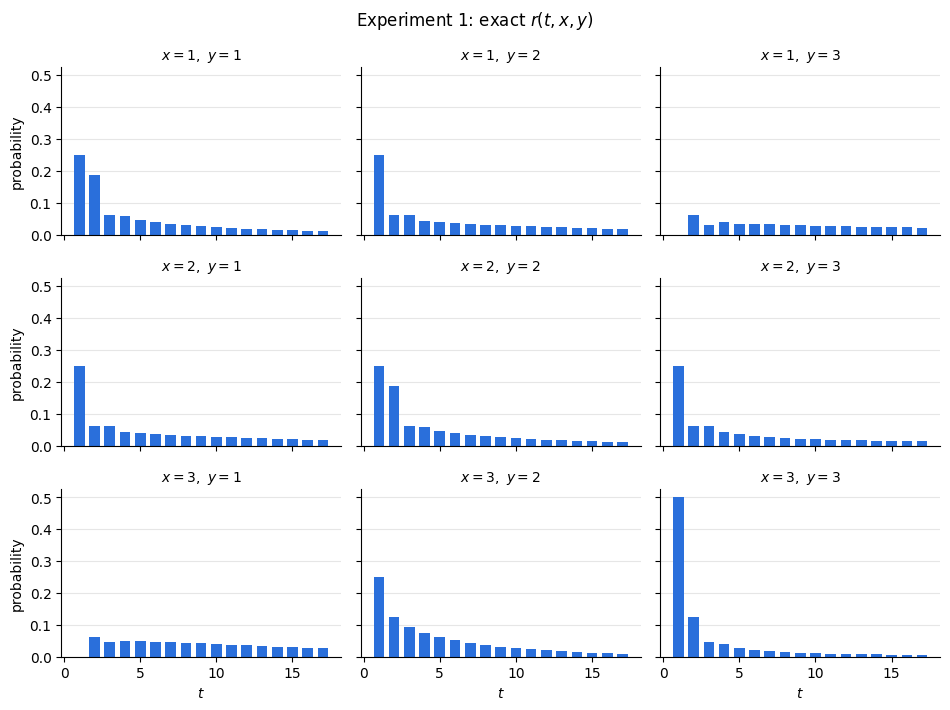

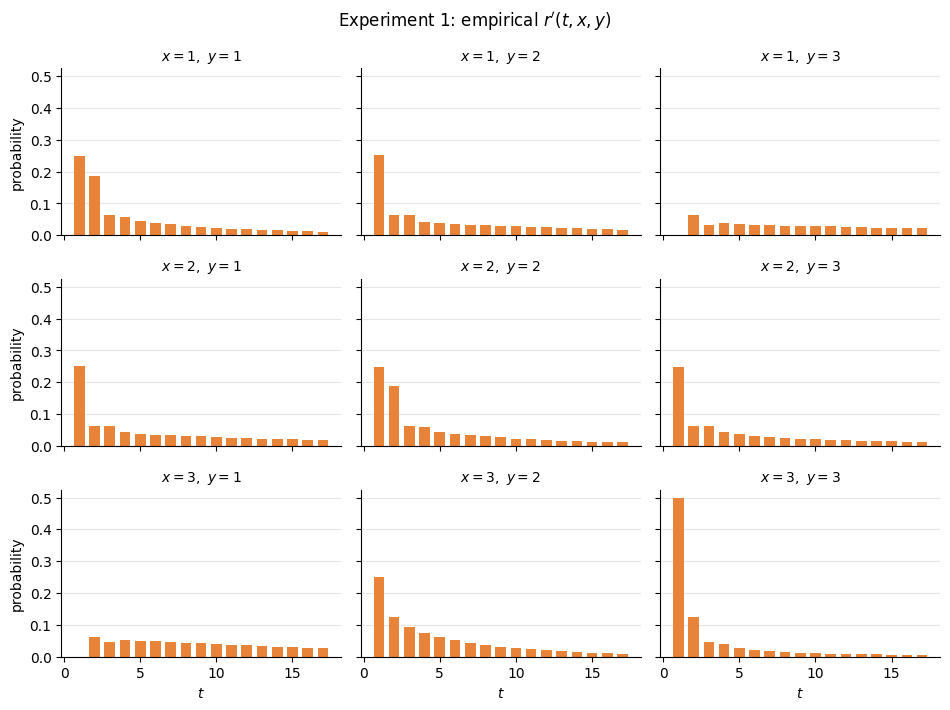

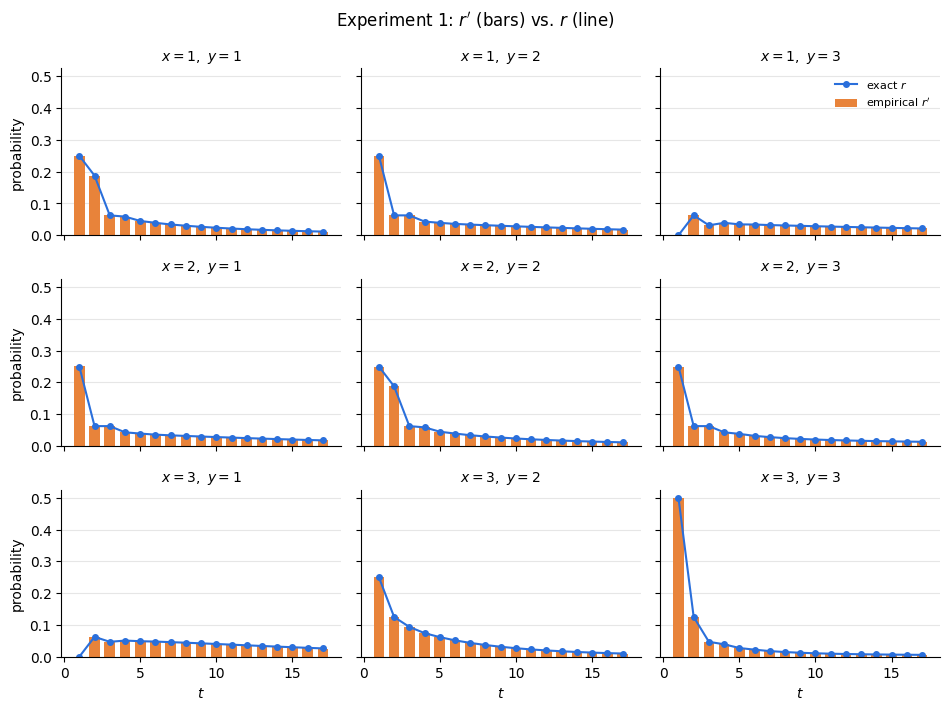

In [11]:
plot_exact_distribution(r1_lit, B1, title="Experiment 1: exact $r(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, title="Experiment 1: empirical $r'(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, r=r1_lit, title="Experiment 1: $r'$ (bars) vs. $r$ (line)")
plt.show()

## Experiment 2: the graph with nine vertices

Varying ground-truth $\mu$ (Section 5.2, Figure 4): a $3 \times 3$ grid with $|B| = 3$ (the top row), $|X\setminus B| = 6$, $w_{xy} = 1$, $\mu_x = \deg(x)$, $T = 9$. Paper FRNE: $0.188348\%$.

Here $\mu_x = \deg(x) = \sum_y w_{xy}$, so Assumption 1 (ii) holds with equality and $p_{xx} = 0$: the walk never stays put. This is the simple random walk (normalized Laplacian).

In [ ]:
grid2    = GridGraph.make_grid(3, 3)
B2_coord = [(0, 0), (0, 1), (0, 2)]
w2       = 1.0
mu2_kind = "deg"
mu2_val  = 1.0
T2       = 9
N2       = 10**6
seed2    = 0

In [ ]:
G2 = GridGraph(grid2, B2_coord, w=w2, mu=mu2_kind, mu_val=mu2_val)
W2, mu2, B2 = G2.W, G2.mu, G2.B
P2 = G2.transition_matrix()
t_max2 = 2 * T2 - 1
print(f"|X| = {len(mu2)}, |B| = {len(B2)}, T = {T2}, t_max = {t_max2}")

plot_graph(grid2, B2, title="Experiment 2: $X$ and $B$")
plot_graph(grid2, B2, values=mu2, title=r"Experiment 2: ground truth $\mu_x = \deg(x)$")
plt.show()

In [20]:
r2 = exact_first_passage_literal(P2, B2, t_max2)
r2_emp = empirical_first_passage(P2, B2, t_max2, n_walks=N2, seed=seed2)

summarize(P2, B2, r2_emp, r2, paper_frne=0.188348)

NameError: name 'r' is not defined

In [ ]:
plot_exact_distribution(r2, B2, title="Experiment 2: exact $r(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, title="Experiment 2: empirical $r'(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, r=r2, title="Experiment 2: $r'$ (bars) vs. $r$ (line)")
plt.show()

NameError: name 'r2' is not defined

## Experiment 3: an irregular shape with variable weights (not in the paper)

A 14-vertex shape on a $4 \times 5$ lattice (`X` = vertex, `o` = empty):

```
X o o o X
X X X X X
X X X X X
o X o X o
```

It has 17 edges. Two "horns" hang off the top corners and two "legs" hang off the bottom. Unlike the paper's experiments, the **edge weights vary**: each $w_{xy}$ is drawn from $\mathrm{Uniform}(0.2, 1)$ with a fixed seed. The centrality is $\mu_x = \deg(x)$. We observe the four tips, $B = \{(0,0), (0,4), (3,1), (3,3)\}$, so $|B| = 4$ and $|X \setminus B| = 10$, and we take $T = |X| = 14$.

Check of Assumption 1 (ii): every $w_{xy} \le 1$, so $\sum_y w_{xy} \le \deg(x) = \mu_x$. Since the weights are $< 1$, $p_{xx} > 0$ at every vertex: the walk is lazy, and lazier where the edges are weak.

To try other weights, set `w3` to a number, a dict `{((r1, c1), (r2, c2)): w}`, a function `w(p, q)` of the two coordinates, or an $n \times n$ matrix.

In [ ]:
pattern3 = ["X o o o X",
            "X X X X X",
            "X X X X X",
            "o X o X o"]
grid3    = GridGraph.grid_from_pattern(pattern3)
B3_coord = [(0, 0), (0, 4), (3, 1), (3, 3)]
w3       = "random"
w3_low, w3_high, w3_seed = 0.2, 1.0, 0
mu3_kind = "deg"
T3       = len(grid3)
N3       = 10**6
seed3    = 0

In [ ]:
G3 = GridGraph(grid3, B3_coord, w=w3, mu=mu3_kind,
               w_low=w3_low, w_high=w3_high, w_seed=w3_seed)
W3, mu3, B3 = G3.W, G3.mu, G3.B
P3 = G3.transition_matrix()
t_max3 = 2 * T3 - 1
print(f"|X| = {len(mu3)}, |E| = {len(G3.edges)}, |B| = {len(B3)}, T = {T3}, t_max = {t_max3}")
print("p_xx (staying probabilities):", torch.diagonal(P3).numpy().round(3))

plot_graph(G3.grid, B3, title="Experiment 3: $X$ and $B$")
plot_graph(G3.grid, B3, values=mu3, W=W3, title=r"Experiment 3: ground truth $\mu_x = \deg(x)$ and $w_{xy}$")
plt.show()

In [ ]:
r3 = exact_first_passage_literal(P3, B3, t_max3)
r3_emp = empirical_first_passage(P3, B3, t_max3, n_walks=N3, seed=seed3)

summarize(P3, B3, r3_emp, r3)

In [ ]:
plot_exact_distribution(r3, B3, title="Experiment 3: exact $r(t, x, y)$")
plot_empirical_distribution(r3_emp, B3, r=r3, title="Experiment 3: $r'$ (bars) vs. $r$ (line)")
plt.show()